# 01 Merge 14 CU-BEMS CSV Tables

本 notebook 完成特征工程前的第一步：把 `Raw Data` 目录下 2018/2019 年、1-7 楼的 14 个 CSV 文件合并成一个统一的原始宽表。

合并原则：

- 每个 CSV 文件代表一个 `year + floor` 的分钟级数据。
- 第一阶段使用纵向合并，而不是横向 join。
- 合并后保留 `year`、`floor`、`source_file`，方便后续追溯。
- 不在这一步把 `NaN` 全部填成 0，因为很多缺失来自不同楼层设备/传感器配置不同。
- 电力数据里的 0 通常表示设备关闭或低负载，不等同于缺失值。

## 1. Import libraries and locate project files

In [1]:
from pathlib import Path
from typing import Optional
import re

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)


PROJECT_NAME = "Artificial Intelligence for Smart-Building Log Analysis"


def find_project_root(start: Optional[Path] = None) -> Path:
    """Find the course project root by searching upward for the project folder."""
    current = (start or Path.cwd()).resolve()
    for path in [current, *current.parents]:
        if path.name == PROJECT_NAME and (path / "Raw Data").exists():
            return path.parent
        if (path / PROJECT_NAME / "Raw Data").exists():
            return path
    raise FileNotFoundError(f"Could not find project root containing '{PROJECT_NAME}/Raw Data'.")


PROJECT_ROOT = find_project_root()
PROJECT_DIR = PROJECT_ROOT / PROJECT_NAME
DATA_DIR = PROJECT_DIR / "Raw Data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PROJECT_ROOT, PROJECT_DIR, DATA_DIR, OUTPUT_DIR

(PosixPath('/Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project'),
 PosixPath('/Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis'),
 PosixPath('/Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/Raw Data'),
 PosixPath('/Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs'))

## 2. Find the 14 source CSV files

In [2]:
csv_files = sorted(DATA_DIR.glob("20??Floor*.csv"))

print(f"Found {len(csv_files)} CSV files")
for file in csv_files:
    print(file.name)

expected_count = 14
if len(csv_files) != expected_count:
    raise ValueError(f"Expected {expected_count} CSV files, but found {len(csv_files)}.")

Found 14 CSV files
2018Floor1.csv
2018Floor2.csv
2018Floor3.csv
2018Floor4.csv
2018Floor5.csv
2018Floor6.csv
2018Floor7.csv
2019Floor1.csv
2019Floor2.csv
2019Floor3.csv
2019Floor4.csv
2019Floor5.csv
2019Floor6.csv
2019Floor7.csv


## 3. Inspect source file structure before merging

这一步用于确认每个文件的行数、列数、时间范围、重复时间戳、缺失值比例和 0 值比例。合并前先做这个检查，可以避免后面特征工程时把数据质量问题误认为真实异常。

In [3]:
file_name_pattern = re.compile(r"(?P<year>\d{4})Floor(?P<floor>\d+)\.csv")


def parse_file_metadata(path: Path) -> dict:
    match = file_name_pattern.fullmatch(path.name)
    if not match:
        raise ValueError(f"Unexpected file name format: {path.name}")
    return {
        "year": int(match.group("year")),
        "floor": int(match.group("floor")),
        "source_file": path.name,
    }


def inspect_csv_file(path: Path) -> dict:
    meta = parse_file_metadata(path)
    df = pd.read_csv(path)
    timestamps = pd.to_datetime(df["Date"], errors="coerce")
    data = df.drop(columns=["Date"])

    valid_timestamps = timestamps.dropna()
    expected_minutes = pd.date_range(valid_timestamps.min(), valid_timestamps.max(), freq="min")
    invalid_timestamps = int(timestamps.isna().sum())
    duplicate_valid_timestamps = int(valid_timestamps.duplicated().sum())
    missing_minutes_in_range = len(expected_minutes) - valid_timestamps.nunique()

    total_cells = data.size
    missing_cells = int(data.isna().sum().sum())
    zero_cells = int((data == 0).sum().sum())

    return {
        **meta,
        "rows": len(df),
        "columns": len(df.columns),
        "start_time": timestamps.min(),
        "end_time": timestamps.max(),
        "invalid_timestamps": invalid_timestamps,
        "duplicate_valid_timestamps": duplicate_valid_timestamps,
        "missing_minutes_in_range": missing_minutes_in_range,
        "missing_value_pct": missing_cells / total_cells if total_cells else np.nan,
        "zero_value_pct": zero_cells / total_cells if total_cells else np.nan,
    }


file_summary = pd.DataFrame(inspect_csv_file(file) for file in csv_files)
file_summary = file_summary.sort_values(["year", "floor"]).reset_index(drop=True)

display(file_summary)

,year,floor,source_file,rows,columns,start_time,end_time,invalid_timestamps,duplicate_valid_timestamps,missing_minutes_in_range,missing_value_pct,zero_value_pct
0,2018,1,2018Floor1.csv,264960,12,2018-07-01,2018-12-31 23:59:00,0,0,0,0.014270,0.063827
1,2018,2,2018Floor2.csv,264960,37,2018-07-01,2018-12-31 23:59:00,0,0,0,0.238233,0.315024
2,2018,3,2018Floor3.csv,264960,30,2018-07-01,2018-12-31 23:59:00,0,0,0,0.402275,0.228962
3,2018,4,2018Floor4.csv,264960,30,2018-07-01,2018-12-31 23:59:00,0,0,0,0.341687,0.267405
4,2018,5,2018Floor5.csv,264960,30,2018-07-01,2018-12-31 23:59:00,0,0,0,0.270161,0.313171
5,2018,6,2018Floor6.csv,264960,30,2018-07-01,2018-12-31 23:59:00,0,0,0,0.255646,0.293905
6,2018,7,2018Floor7.csv,264960,30,2018-07-01,2018-12-31 23:59:00,0,0,0,0.254146,0.278145
7,2019,1,2019Floor1.csv,525600,12,2019-01-01,2019-12-31 23:59:00,0,0,0,0.001360,0.080815
8,2019,2,2019Floor2.csv,525600,37,2019-01-01,2019-12-31 23:59:00,0,0,0,0.071473,0.324505
9,2019,3,2019Floor3.csv,525600,30,2019-01-01,2019-12-31 23:59:00,0,0,0,0.110790,0.335303


## 4. Preview columns by floor

不同楼层的列并不完全一样。比如 Floor 1 没有完整的温度、湿度、照度传感器列；Floor 2 有很多 AC 设备列。因此合并后的宽表出现 `NaN` 是正常现象。

In [4]:
schema_rows = []

for file in csv_files:
    meta = parse_file_metadata(file)
    columns = pd.read_csv(file, nrows=0).columns.tolist()
    schema_rows.append({
        **meta,
        "column_count": len(columns),
        "data_columns": columns[1:],
    })

schema_summary = pd.DataFrame(schema_rows).sort_values(["year", "floor"]).reset_index(drop=True)
display(schema_summary[["year", "floor", "source_file", "column_count"]])

# Show the first file's columns as an example.
schema_summary.loc[0, "data_columns"]

,year,floor,source_file,column_count
0,2018,1,2018Floor1.csv,12
1,2018,2,2018Floor2.csv,37
2,2018,3,2018Floor3.csv,30
3,2018,4,2018Floor4.csv,30
4,2018,5,2018Floor5.csv,30
5,2018,6,2018Floor6.csv,30
6,2018,7,2018Floor7.csv,30
7,2019,1,2019Floor1.csv,12
8,2019,2,2019Floor2.csv,37
9,2019,3,2019Floor3.csv,30


['z1_Light(kW)',
 'z1_Plug(kW)',
 'z2_AC1(kW)',
 'z2_AC2(kW)',
 'z2_AC3(kW)',
 'z2_AC4(kW)',
 'z2_Light(kW)',
 'z2_Plug(kW)',
 'z3_Light(kW)',
 'z3_Plug(kW)',
 'z4_Light(kW)']

## 5. Load and vertically merge the 14 CSV files

这里使用 `pd.concat` 做纵向合并。每一行仍然表示某一分钟的数据，只是额外增加了 `year`、`floor` 和 `source_file`。

In [5]:
def downcast_numeric_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Reduce memory use while keeping numeric values suitable for analysis."""
    integer_like_cols = {
        "year", "floor", "zone",
        "ac_device_count", "ac_active_count",
        "has_light_meter", "has_plug_meter", "has_environment_sensor",
        "missing_ac_power_flag", "missing_light_power_flag", "missing_plug_power_flag",
        "missing_temperature_flag", "missing_humidity_flag", "missing_lux_flag",
        "month", "day", "hour", "minute", "day_of_week",
        "is_weekend", "is_work_hour", "minute_of_day",
    }
    numeric_cols = df.select_dtypes(include=["number"]).columns
    for col in numeric_cols:
        if col in integer_like_cols:
            df[col] = pd.to_numeric(df[col], downcast="integer")
        else:
            df[col] = pd.to_numeric(df[col], downcast="float")
    return df


def load_floor_csv(path: Path) -> pd.DataFrame:
    meta = parse_file_metadata(path)

    df = pd.read_csv(path)
    df["timestamp"] = pd.to_datetime(df["Date"], errors="coerce")
    df = df.drop(columns=["Date"])

    # Rows with invalid timestamps cannot be used in minute-level feature engineering.
    df = df.dropna(subset=["timestamp"])

    # If a source file contains duplicate valid timestamps, keep the first row and document it in the QA table.
    df = df.drop_duplicates(subset=["timestamp"], keep="first")
    df = df.sort_values("timestamp").reset_index(drop=True)

    df.insert(0, "source_file", meta["source_file"])
    df.insert(0, "floor", meta["floor"])
    df.insert(0, "year", meta["year"])

    return downcast_numeric_columns(df)


parts = []
for file in csv_files:
    print(f"Loading {file.name} ...")
    parts.append(load_floor_csv(file))

combined_wide = pd.concat(parts, ignore_index=True, sort=False)
combined_wide = combined_wide.sort_values(["timestamp", "floor", "year"]).reset_index(drop=True)

print("Merged shape:", combined_wide.shape)
display(combined_wide.head())

Loading 2018Floor1.csv ...
Loading 2018Floor2.csv ...


Loading 2018Floor3.csv ...


Loading 2018Floor4.csv ...


Loading 2018Floor5.csv ...


Loading 2018Floor6.csv ...


...

Loading 2019Floor5.csv ...


Loading 2019Floor6.csv ...


Loading 2019Floor7.csv ...


Merged shape: (5432488, 52)


,year,floor,source_file,z1_Light(kW),z1_Plug(kW),z2_AC1(kW),z2_AC2(kW),z2_AC3(kW),z2_AC4(kW),z2_Light(kW),z2_Plug(kW),z3_Light(kW),z3_Plug(kW),z4_Light(kW),timestamp,z1_AC1(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_AC5(kW),z2_AC6(kW),z2_AC7(kW),z2_AC8(kW),z2_AC9(kW),z2_AC10(kW),z2_AC11(kW),z2_AC12(kW),z2_AC13(kW),z2_AC14(kW),z2_S1(degC),z2_S1(RH%),z2_S1(lux),z3_S1(degC),z3_S1(RH%),z3_S1(lux),z4_AC1(kW),z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux),z1_AC2(kW),z1_AC3(kW),z1_AC4(kW),z5_AC1(kW),z5_Light(kW),z5_Plug(kW),z5_S1(degC),z5_S1(RH%),z5_S1(lux),z4_AC2(kW),z4_AC3(kW),z4_AC4(kW)
0,2018,1,2018Floor1.csv,12.94,18.559999,45.240002,0.01,0.01,0.0,13.76,17.639999,10.92,0.89,35.759998,2018-07-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2018,2,2018Floor2.csv,0.01,0.150000,1.080000,0.00,0.00,0.0,0.00,0.100000,0.01,0.32,0.000000,2018-07-01,0.0,28.360001,58.930000,0.0,1.29,1.26,0.87,0.92,0.96,1.07,0.0,0.0,0.0,0.0,28.850000,64.889999,0.0,29.299999,68.220001,0.0,0.0,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2018,3,2018Floor3.csv,0.00,0.030000,0.000000,NaN,NaN,NaN,0.00,0.030000,0.01,0.26,0.000000,2018-07-01,0.0,28.440001,60.669998,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.670000,63.369999,0.0,NaN,NaN,NaN,0.0,0.02,27.690001,65.660004,0.0,0.0,0.0,0.07,0.0,0.0,0.02,26.879999,71.160004,0.0,NaN,NaN,NaN
3,2018,4,2018Floor4.csv,0.00,0.220000,0.000000,NaN,NaN,NaN,0.00,0.150000,0.05,0.36,0.000000,2018-07-01,0.0,28.280001,62.500000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.309999,65.739998,0.0,NaN,NaN,NaN,0.0,0.07,NaN,NaN,NaN,0.0,0.0,8.74,0.0,0.0,0.15,27.730000,62.860001,0.0,NaN,NaN,NaN
4,2018,5,2018Floor5.csv,0.34,0.170000,0.000000,NaN,NaN,NaN,0.00,0.030000,0.02,0.26,0.000000,2018-07-01,0.0,27.540001,68.290001,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.110001,70.500000,0.0,NaN,NaN,NaN,0.0,0.24,27.549999,70.360001,0.0,0.0,0.0,0.00,0.0,0.0,0.01,28.160000,68.510002,1.0,NaN,NaN,NaN


## 6. Validate the merged table

In [6]:
expected_rows_after_cleaning = (
    file_summary["rows"].sum()
    - file_summary["invalid_timestamps"].sum()
    - file_summary["duplicate_valid_timestamps"].sum()
)
actual_rows = len(combined_wide)

print("Expected rows after timestamp cleaning:", f"{expected_rows_after_cleaning:,}")
print("Actual merged rows:", f"{actual_rows:,}")

if actual_rows != expected_rows_after_cleaning:
    raise AssertionError("Merged row count does not match expected row count after timestamp cleaning.")

duplicate_key_count = combined_wide.duplicated(subset=["source_file", "timestamp"]).sum()
print("Duplicate source_file + timestamp rows:", duplicate_key_count)

display(combined_wide[["year", "floor", "source_file", "timestamp"]].head())
display(combined_wide[["year", "floor", "source_file", "timestamp"]].tail())

Expected rows after timestamp cleaning: 5,432,488
Actual merged rows: 5,432,488


Duplicate source_file + timestamp rows: 0


,year,floor,source_file,timestamp
0,2018,1,2018Floor1.csv,2018-07-01
1,2018,2,2018Floor2.csv,2018-07-01
2,2018,3,2018Floor3.csv,2018-07-01
3,2018,4,2018Floor4.csv,2018-07-01
4,2018,5,2018Floor5.csv,2018-07-01


,year,floor,source_file,timestamp
5432483,2019,2,2019Floor2.csv,2019-12-31 23:59:00
5432484,2019,3,2019Floor3.csv,2019-12-31 23:59:00
5432485,2019,4,2019Floor4.csv,2019-12-31 23:59:00
5432486,2019,5,2019Floor5.csv,2019-12-31 23:59:00
5432487,2019,7,2019Floor7.csv,2019-12-31 23:59:00


## 7. Save the merged raw table

优先保存为 Parquet，因为它比 CSV 更适合这种大体量分钟级数据。如果当前环境没有 Parquet 引擎，则自动保存为压缩 CSV。

In [7]:
parquet_path = OUTPUT_DIR / "combined_wide_2018_2019.parquet"
csv_gz_path = OUTPUT_DIR / "combined_wide_2018_2019.csv.gz"

try:
    combined_wide.to_parquet(parquet_path, index=False)
    saved_path = parquet_path
except Exception as exc:
    print("Parquet save failed. Falling back to compressed CSV.")
    print(type(exc).__name__, exc)
    combined_wide.to_csv(csv_gz_path, index=False, compression="gzip")
    saved_path = csv_gz_path

print("Saved merged table to:", saved_path)
print("File size MB:", round(saved_path.stat().st_size / 1024 / 1024, 2))

Parquet save failed. Falling back to compressed CSV.
ImportError Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.


Saved merged table to: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/combined_wide_2018_2019.csv.gz
File size MB: 111.08


## 8. Recommended next step: convert wide table to modelling-friendly structure

上面生成的 `combined_wide` 是第一阶段合并表，适合做原始数据归档和基础检查。下一步做特征工程时，建议再转换成以下两类表：

1. `long_df`: `timestamp + floor + zone + system + device_id + variable + unit + value`
2. `features_zone_minute`: `timestamp + floor + zone` 粒度的建模特征表

下面的代码先给出列名解析函数，后续可以在第二个 notebook 中继续完成完整特征工程。

In [27]:
combined_wide.shape

(5432488, 52)

In [8]:
column_pattern = re.compile(r"^z(?P<zone>\d+)_(?P<name>.+?)\((?P<unit>.+)\)$")


def parse_measurement_column(column_name: str) -> dict:
    match = column_pattern.fullmatch(column_name)
    if not match:
        return {
            "raw_variable": column_name,
            "zone": pd.NA,
            "system": "Unknown",
            "device_id": pd.NA,
            "variable": "unknown",
            "unit": pd.NA,
        }

    zone = int(match.group("zone"))
    name = match.group("name")
    unit = match.group("unit")

    if name.startswith("AC"):
        system = "AC"
        device_id = name
        variable = "power_kw"
    elif name == "Light":
        system = "Light"
        device_id = "Light"
        variable = "power_kw"
    elif name == "Plug":
        system = "Plug"
        device_id = "Plug"
        variable = "power_kw"
    elif name.startswith("S") and unit == "degC":
        system = "Sensor"
        device_id = name
        variable = "temperature_c"
    elif name.startswith("S") and unit == "RH%":
        system = "Sensor"
        device_id = name
        variable = "humidity_pct"
    elif name.startswith("S") and unit == "lux":
        system = "Sensor"
        device_id = name
        variable = "lux"
    else:
        system = "Unknown"
        device_id = name
        variable = unit

    return {
        "raw_variable": column_name,
        "zone": zone,
        "system": system,
        "device_id": device_id,
        "variable": variable,
        "unit": unit,
    }


measurement_columns = [
    col for col in combined_wide.columns
    if col not in ["year", "floor", "source_file", "timestamp"]
]

column_dictionary = pd.DataFrame(parse_measurement_column(col) for col in measurement_columns)
display(column_dictionary.head(20))

,raw_variable,zone,system,device_id,variable,unit
0,z1_Light(kW),1,Light,Light,power_kw,kW
1,z1_Plug(kW),1,Plug,Plug,power_kw,kW
2,z2_AC1(kW),2,AC,AC1,power_kw,kW
3,z2_AC2(kW),2,AC,AC2,power_kw,kW
4,z2_AC3(kW),2,AC,AC3,power_kw,kW
5,z2_AC4(kW),2,AC,AC4,power_kw,kW
6,z2_Light(kW),2,Light,Light,power_kw,kW
7,z2_Plug(kW),2,Plug,Plug,power_kw,kW
8,z3_Light(kW),3,Light,Light,power_kw,kW
9,z3_Plug(kW),3,Plug,Plug,power_kw,kW


## 9. Create the first zone-minute feature table

这一节生成第一版建模特征表，粒度是 `timestamp + floor + zone`。

为了避免完整 `long_df` 过大，这里不把所有设备列一次性展开落盘，而是直接从每个原始 CSV 聚合出 zone-minute 特征。这样仍然保留了列解析逻辑，也更适合下一步 EDA 和异常检测。

In [9]:
import gzip

COLUMN_DICTIONARY_PATH = OUTPUT_DIR / "column_dictionary.csv"
FEATURE_OUTPUT_PATH = OUTPUT_DIR / "features_zone_minute_2018_2019.csv.gz"

column_dictionary.to_csv(COLUMN_DICTIONARY_PATH, index=False)

print("Saved column dictionary to:", COLUMN_DICTIONARY_PATH)
print("Feature output will be saved to:", FEATURE_OUTPUT_PATH)

Saved column dictionary to: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/column_dictionary.csv
Feature output will be saved to: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/features_zone_minute_2018_2019.csv.gz


In [10]:
def sum_columns(df: pd.DataFrame, columns: list[str]) -> pd.Series:
    if not columns:
        return pd.Series(np.nan, index=df.index)
    return df[columns].sum(axis=1, min_count=1)


def mean_columns(df: pd.DataFrame, columns: list[str]) -> pd.Series:
    if not columns:
        return pd.Series(np.nan, index=df.index)
    return df[columns].mean(axis=1)


def active_count(df: pd.DataFrame, columns: list[str]) -> pd.Series:
    if not columns:
        return pd.Series(0, index=df.index, dtype="int16")
    return (df[columns].fillna(0) > 0).sum(axis=1).astype("int16")


def build_zone_minute_features_from_file(path: Path) -> pd.DataFrame:
    meta = parse_file_metadata(path)
    df = pd.read_csv(path)
    df["timestamp"] = pd.to_datetime(df["Date"], errors="coerce")
    df = df.drop(columns=["Date"])
    df = df.dropna(subset=["timestamp"])
    df = df.drop_duplicates(subset=["timestamp"], keep="first")
    df = df.sort_values("timestamp").reset_index(drop=True)

    measurement_cols = [col for col in df.columns if col != "timestamp"]
    local_dictionary = pd.DataFrame(parse_measurement_column(col) for col in measurement_cols)
    zones = sorted(local_dictionary["zone"].dropna().astype(int).unique())

    feature_parts = []
    for zone in zones:
        zone_dict = local_dictionary[local_dictionary["zone"] == zone]
        ac_cols = zone_dict.loc[zone_dict["system"] == "AC", "raw_variable"].tolist()
        light_cols = zone_dict.loc[zone_dict["system"] == "Light", "raw_variable"].tolist()
        plug_cols = zone_dict.loc[zone_dict["system"] == "Plug", "raw_variable"].tolist()
        temp_cols = zone_dict.loc[zone_dict["variable"] == "temperature_c", "raw_variable"].tolist()
        humidity_cols = zone_dict.loc[zone_dict["variable"] == "humidity_pct", "raw_variable"].tolist()
        lux_cols = zone_dict.loc[zone_dict["variable"] == "lux", "raw_variable"].tolist()

        features = pd.DataFrame({
            "timestamp": df["timestamp"],
            "year": meta["year"],
            "floor": meta["floor"],
            "zone": zone,
            "source_file": meta["source_file"],
        })

        features["ac_power_kw"] = sum_columns(df, ac_cols)
        features["light_power_kw"] = sum_columns(df, light_cols)
        features["plug_power_kw"] = sum_columns(df, plug_cols)
        features["total_power_kw"] = features[["ac_power_kw", "light_power_kw", "plug_power_kw"]].sum(axis=1, min_count=1)

        features["temperature_c"] = mean_columns(df, temp_cols)
        features["humidity_pct"] = mean_columns(df, humidity_cols)
        features["lux"] = mean_columns(df, lux_cols)

        features["ac_device_count"] = len(ac_cols)
        features["ac_active_count"] = active_count(df, ac_cols)
        features["has_light_meter"] = int(bool(light_cols))
        features["has_plug_meter"] = int(bool(plug_cols))
        features["has_environment_sensor"] = int(bool(temp_cols or humidity_cols or lux_cols))

        features["missing_ac_power_flag"] = features["ac_power_kw"].isna().astype("int8")
        features["missing_light_power_flag"] = features["light_power_kw"].isna().astype("int8")
        features["missing_plug_power_flag"] = features["plug_power_kw"].isna().astype("int8")
        features["missing_temperature_flag"] = features["temperature_c"].isna().astype("int8")
        features["missing_humidity_flag"] = features["humidity_pct"].isna().astype("int8")
        features["missing_lux_flag"] = features["lux"].isna().astype("int8")

        features["month"] = features["timestamp"].dt.month.astype("int8")
        features["day"] = features["timestamp"].dt.day.astype("int8")
        features["hour"] = features["timestamp"].dt.hour.astype("int8")
        features["minute"] = features["timestamp"].dt.minute.astype("int8")
        features["day_of_week"] = features["timestamp"].dt.dayofweek.astype("int8")
        features["is_weekend"] = features["day_of_week"].isin([5, 6]).astype("int8")
        features["is_work_hour"] = features["hour"].between(8, 18).astype("int8")
        features["minute_of_day"] = (features["hour"] * 60 + features["minute"]).astype("int16")

        feature_parts.append(downcast_numeric_columns(features))

    return pd.concat(feature_parts, ignore_index=True)


preview_features = build_zone_minute_features_from_file(csv_files[0])
print("Preview source:", csv_files[0].name)
print("Preview shape:", preview_features.shape)
display(preview_features.head())

Preview source: 2018Floor1.csv
Preview shape: (1059840, 31)


,timestamp,year,floor,zone,source_file,ac_power_kw,light_power_kw,plug_power_kw,total_power_kw,temperature_c,humidity_pct,lux,ac_device_count,ac_active_count,has_light_meter,has_plug_meter,has_environment_sensor,missing_ac_power_flag,missing_light_power_flag,missing_plug_power_flag,missing_temperature_flag,missing_humidity_flag,missing_lux_flag,month,day,hour,minute,day_of_week,is_weekend,is_work_hour,minute_of_day
0,2018-07-01 00:00:00,2018,1,1,2018Floor1.csv,NaN,12.94,18.559999,31.500000,NaN,NaN,NaN,0,0,1,1,0,1,0,0,1,1,1,7,1,0,0,6,1,0,0
1,2018-07-01 00:01:00,2018,1,1,2018Floor1.csv,NaN,12.97,18.549999,31.520000,NaN,NaN,NaN,0,0,1,1,0,1,0,0,1,1,1,7,1,0,1,6,1,0,1
2,2018-07-01 00:02:00,2018,1,1,2018Floor1.csv,NaN,12.97,18.549999,31.520000,NaN,NaN,NaN,0,0,1,1,0,1,0,0,1,1,1,7,1,0,2,6,1,0,2
3,2018-07-01 00:03:00,2018,1,1,2018Floor1.csv,NaN,12.98,18.580000,31.559999,NaN,NaN,NaN,0,0,1,1,0,1,0,0,1,1,1,7,1,0,3,6,1,0,3
4,2018-07-01 00:04:00,2018,1,1,2018Floor1.csv,NaN,13.01,18.600000,31.610001,NaN,NaN,NaN,0,0,1,1,0,1,0,0,1,1,1,7,1,0,4,6,1,0,4


## 10. Save the feature table incrementally

输出文件是 `features_zone_minute_2018_2019.csv.gz`。每一行代表某一分钟、某一楼层、某一个 zone 的聚合特征。

In [11]:
feature_run_summary = []
total_feature_rows = 0

with gzip.open(FEATURE_OUTPUT_PATH, "wt", newline="") as handle:
    for index, file in enumerate(csv_files):
        print(f"Creating zone-minute features from {file.name} ...")
        feature_part = build_zone_minute_features_from_file(file)
        feature_part.to_csv(handle, index=False, header=(index == 0))

        feature_run_summary.append({
            "source_file": file.name,
            "feature_rows": len(feature_part),
            "floors": feature_part["floor"].nunique(),
            "zones": feature_part["zone"].nunique(),
            "start_time": feature_part["timestamp"].min(),
            "end_time": feature_part["timestamp"].max(),
        })
        total_feature_rows += len(feature_part)

        del feature_part

feature_run_summary = pd.DataFrame(feature_run_summary)

print("Total feature rows:", f"{total_feature_rows:,}")
print("Saved feature table to:", FEATURE_OUTPUT_PATH)
print("Feature file size MB:", round(FEATURE_OUTPUT_PATH.stat().st_size / 1024 / 1024, 2))
display(feature_run_summary)

Creating zone-minute features from 2018Floor1.csv ...


Creating zone-minute features from 2018Floor2.csv ...


Creating zone-minute features from 2018Floor3.csv ...


Creating zone-minute features from 2018Floor4.csv ...


Creating zone-minute features from 2018Floor5.csv ...


...

Creating zone-minute features from 2019Floor5.csv ...


Creating zone-minute features from 2019Floor6.csv ...


Creating zone-minute features from 2019Floor7.csv ...


Total feature rows: 25,581,320
Saved feature table to: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/features_zone_minute_2018_2019.csv.gz
Feature file size MB: 298.05


,source_file,feature_rows,floors,zones,start_time,end_time
0,2018Floor1.csv,1059840,1,4,2018-07-01,2018-12-31 23:59:00
1,2018Floor2.csv,1059840,1,4,2018-07-01,2018-12-31 23:59:00
2,2018Floor3.csv,1324800,1,5,2018-07-01,2018-12-31 23:59:00
3,2018Floor4.csv,1324800,1,5,2018-07-01,2018-12-31 23:59:00
4,2018Floor5.csv,1324800,1,5,2018-07-01,2018-12-31 23:59:00
5,2018Floor6.csv,1324800,1,5,2018-07-01,2018-12-31 23:59:00
6,2018Floor7.csv,1324800,1,5,2018-07-01,2018-12-31 23:59:00
7,2019Floor1.csv,2102400,1,4,2019-01-01,2019-12-31 23:59:00
8,2019Floor2.csv,2102400,1,4,2019-01-01,2019-12-31 23:59:00
9,2019Floor3.csv,2628000,1,5,2019-01-01,2019-12-31 23:59:00


## 11. Verify the saved feature table

最后做一个轻量验证：读取前几行、统计列名，并检查输出文件中的行数是否等于刚才生成的 `total_feature_rows`。

In [12]:
features_preview = pd.read_csv(FEATURE_OUTPUT_PATH, nrows=10)

with gzip.open(FEATURE_OUTPUT_PATH, "rt") as handle:
    saved_feature_rows = sum(1 for _ in handle) - 1

print("Saved feature rows:", f"{saved_feature_rows:,}")
if saved_feature_rows != total_feature_rows:
    raise AssertionError("Saved feature row count does not match generated feature row count.")

print("Feature columns:")
print(list(features_preview.columns))
display(features_preview)

Saved feature rows: 25,581,320
Feature columns:
['timestamp', 'year', 'floor', 'zone', 'source_file', 'ac_power_kw', 'light_power_kw', 'plug_power_kw', 'total_power_kw', 'temperature_c', 'humidity_pct', 'lux', 'ac_device_count', 'ac_active_count', 'has_light_meter', 'has_plug_meter', 'has_environment_sensor', 'missing_ac_power_flag', 'missing_light_power_flag', 'missing_plug_power_flag', 'missing_temperature_flag', 'missing_humidity_flag', 'missing_lux_flag', 'month', 'day', 'hour', 'minute', 'day_of_week', 'is_weekend', 'is_work_hour', 'minute_of_day']


,timestamp,year,floor,zone,source_file,ac_power_kw,light_power_kw,plug_power_kw,total_power_kw,temperature_c,humidity_pct,lux,ac_device_count,ac_active_count,has_light_meter,has_plug_meter,has_environment_sensor,missing_ac_power_flag,missing_light_power_flag,missing_plug_power_flag,missing_temperature_flag,missing_humidity_flag,missing_lux_flag,month,day,hour,minute,day_of_week,is_weekend,is_work_hour,minute_of_day
0,2018-07-01 00:00:00,2018,1,1,2018Floor1.csv,NaN,12.94,18.56,31.50,NaN,NaN,NaN,0,0,1,1,0,1,0,0,1,1,1,7,1,0,0,6,1,0,0
1,2018-07-01 00:01:00,2018,1,1,2018Floor1.csv,NaN,12.97,18.55,31.52,NaN,NaN,NaN,0,0,1,1,0,1,0,0,1,1,1,7,1,0,1,6,1,0,1
2,2018-07-01 00:02:00,2018,1,1,2018Floor1.csv,NaN,12.97,18.55,31.52,NaN,NaN,NaN,0,0,1,1,0,1,0,0,1,1,1,7,1,0,2,6,1,0,2
3,2018-07-01 00:03:00,2018,1,1,2018Floor1.csv,NaN,12.98,18.58,31.56,NaN,NaN,NaN,0,0,1,1,0,1,0,0,1,1,1,7,1,0,3,6,1,0,3
4,2018-07-01 00:04:00,2018,1,1,2018Floor1.csv,NaN,13.01,18.60,31.61,NaN,NaN,NaN,0,0,1,1,0,1,0,0,1,1,1,7,1,0,4,6,1,0,4
5,2018-07-01 00:05:00,2018,1,1,2018Floor1.csv,NaN,12.98,18.55,31.53,NaN,NaN,NaN,0,0,1,1,0,1,0,0,1,1,1,7,1,0,5,6,1,0,5
6,2018-07-01 00:06:00,2018,1,1,2018Floor1.csv,NaN,12.97,18.56,31.53,NaN,NaN,NaN,0,0,1,1,0,1,0,0,1,1,1,7,1,0,6,6,1,0,6
7,2018-07-01 00:07:00,2018,1,1,2018Floor1.csv,NaN,12.98,18.64,31.62,NaN,NaN,NaN,0,0,1,1,0,1,0,0,1,1,1,7,1,0,7,6,1,0,7
8,2018-07-01 00:08:00,2018,1,1,2018Floor1.csv,NaN,12.99,18.65,31.64,NaN,NaN,NaN,0,0,1,1,0,1,0,0,1,1,1,7,1,0,8,6,1,0,8
9,2018-07-01 00:09:00,2018,1,1,2018Floor1.csv,NaN,13.00,18.66,31.66,NaN,NaN,NaN,0,0,1,1,0,1,0,0,1,1,1,7,1,0,9,6,1,0,9


## Notes for feature engineering

- `combined_wide` 是第一步总表，不建议直接拿它训练模型。
- 后续建模建议以 `timestamp + floor + zone` 为主键生成区域级特征。
- AC 多设备列可以先在设备级保留，再聚合成 `ac_power_kw`、`ac_device_count`、`ac_active_count`。
- Light 和 Plug 可以聚合成 `light_power_kw`、`plug_power_kw`。
- 温度、湿度、照度可以按 zone 聚合为 `temperature_c`、`humidity_pct`、`lux`。
- 对缺失值建议添加 missing flags，例如 `missing_temperature_flag`，不要在第一步粗暴填 0。
- `2019Floor6.csv` 时间范围短于其他 2019 文件，且原始文件中有 1 行无效时间戳，合并时已删除；做全年比较时要单独说明。

## 12. Exploratory Data Analysis (EDA)

这一节开始做特征工程后的第一轮 EDA。目标不是直接判断异常，而是先建立“正常运行模式”的基线理解：哪些楼层和 zone 能耗较高、工作时间与非工作时间是否不同、weekday/weekend 是否不同、哪些变量缺失严重。

In [13]:
EDA_DIR = OUTPUT_DIR / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_INPUT_PATH = OUTPUT_DIR / "features_zone_minute_2018_2019.csv.gz"
if not FEATURE_INPUT_PATH.exists():
    raise FileNotFoundError(f"Feature table not found: {FEATURE_INPUT_PATH}")

feature_columns = pd.read_csv(FEATURE_INPUT_PATH, nrows=0).columns.tolist()
print("Feature input:", FEATURE_INPUT_PATH)
print("EDA output directory:", EDA_DIR)
print("Feature columns:", len(feature_columns))
print(feature_columns)

Feature input: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/features_zone_minute_2018_2019.csv.gz
EDA output directory: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/eda
Feature columns: 31
['timestamp', 'year', 'floor', 'zone', 'source_file', 'ac_power_kw', 'light_power_kw', 'plug_power_kw', 'total_power_kw', 'temperature_c', 'humidity_pct', 'lux', 'ac_device_count', 'ac_active_count', 'has_light_meter', 'has_plug_meter', 'has_environment_sensor', 'missing_ac_power_flag', 'missing_light_power_flag', 'missing_plug_power_flag', 'missing_temperature_flag', 'missing_humidity_flag', 'missing_lux_flag', 'month', 'day', 'hour', 'minute', 'day_of_week', 'is_weekend', 'is_work_hour', 'minute_of_day']


## 13. Build EDA summary tables

这里使用 chunk 方式读取 `features_zone_minute_2018_2019.csv.gz`，避免一次性加载 2500 多万行数据。输出的 summary 表会保存为 CSV，后续写报告或画图可以直接复用。

In [14]:
VALUE_COLUMNS = [
    "ac_power_kw", "light_power_kw", "plug_power_kw", "total_power_kw",
    "temperature_c", "humidity_pct", "lux",
]

MISSING_COLUMNS = [
    "ac_power_kw", "light_power_kw", "plug_power_kw", "total_power_kw",
    "temperature_c", "humidity_pct", "lux",
]

GROUP_SPECS = {
    "floor_summary": ["floor"],
    "zone_summary": ["floor", "zone"],
    "hour_summary": ["hour"],
    "day_of_week_summary": ["day_of_week"],
    "work_hour_summary": ["is_work_hour"],
    "weekend_summary": ["is_weekend"],
    "floor_hour_summary": ["floor", "hour"],
}


def chunk_group_agg(chunk: pd.DataFrame, group_keys: list[str], value_cols: list[str]) -> pd.DataFrame:
    grouped = chunk.groupby(group_keys, dropna=False)
    rows = grouped.size().rename("row_count")
    sums = grouped[value_cols].sum(min_count=1).add_suffix("_sum")
    counts = grouped[value_cols].count().add_suffix("_count")
    maxima = grouped[value_cols].max().add_suffix("_max")
    return pd.concat([rows, sums, counts, maxima], axis=1)


def finalize_group_summary(parts: list[pd.DataFrame], group_keys: list[str], value_cols: list[str]) -> pd.DataFrame:
    combined = pd.concat(parts).fillna(0)
    level = list(range(len(group_keys)))

    sum_cols = [f"{col}_sum" for col in value_cols]
    count_cols = [f"{col}_count" for col in value_cols]
    max_cols = [f"{col}_max" for col in value_cols]

    totals = combined[["row_count", *sum_cols, *count_cols]].groupby(level=level).sum()
    maxima = combined[max_cols].replace(0, np.nan).groupby(level=level).max()
    summary = pd.concat([totals, maxima], axis=1).reset_index()

    for col in value_cols:
        count = summary[f"{col}_count"].replace(0, np.nan)
        summary[f"{col}_mean"] = summary[f"{col}_sum"] / count

    ordered_cols = [*group_keys, "row_count"]
    for col in value_cols:
        ordered_cols.extend([f"{col}_mean", f"{col}_max", f"{col}_count"])

    return summary[ordered_cols].sort_values(group_keys).reset_index(drop=True)


group_parts = {name: [] for name in GROUP_SPECS}
missing_counts = pd.Series(0, index=MISSING_COLUMNS, dtype="int64")
non_missing_counts = pd.Series(0, index=MISSING_COLUMNS, dtype="int64")
total_rows = 0
min_timestamp = None
max_timestamp = None

usecols = sorted(set(["timestamp", *VALUE_COLUMNS, *MISSING_COLUMNS, *sum(GROUP_SPECS.values(), [])]))

for chunk_number, chunk in enumerate(pd.read_csv(FEATURE_INPUT_PATH, usecols=usecols, chunksize=1_000_000), start=1):
    print(f"Processing chunk {chunk_number:,} with {len(chunk):,} rows ...")
    total_rows += len(chunk)

    chunk_min_time = chunk["timestamp"].min()
    chunk_max_time = chunk["timestamp"].max()
    min_timestamp = chunk_min_time if min_timestamp is None else min(min_timestamp, chunk_min_time)
    max_timestamp = chunk_max_time if max_timestamp is None else max(max_timestamp, chunk_max_time)

    missing_counts += chunk[MISSING_COLUMNS].isna().sum()
    non_missing_counts += chunk[MISSING_COLUMNS].notna().sum()

    for name, group_keys in GROUP_SPECS.items():
        group_parts[name].append(chunk_group_agg(chunk, group_keys, VALUE_COLUMNS))

eda_overview = pd.DataFrame({
    "metric": ["total_rows", "start_timestamp", "end_timestamp", "floor_count", "zone_count"],
    "value": [
        total_rows,
        min_timestamp,
        max_timestamp,
        "see floor_summary.csv",
        "see zone_summary.csv",
    ],
})

missing_summary = pd.DataFrame({
    "variable": MISSING_COLUMNS,
    "missing_count": missing_counts.values,
    "non_missing_count": non_missing_counts.values,
})
missing_summary["missing_pct"] = missing_summary["missing_count"] / total_rows

eda_overview.to_csv(EDA_DIR / "eda_overview.csv", index=False)
missing_summary.to_csv(EDA_DIR / "missing_summary.csv", index=False)

summary_tables = {}
for name, parts in group_parts.items():
    summary = finalize_group_summary(parts, GROUP_SPECS[name], VALUE_COLUMNS)
    summary_tables[name] = summary
    summary.to_csv(EDA_DIR / f"{name}.csv", index=False)

print("Total rows processed:", f"{total_rows:,}")
print("Time range:", min_timestamp, "->", max_timestamp)
print("Saved EDA summaries to:", EDA_DIR)
display(missing_summary)
display(summary_tables["floor_summary"])

Processing chunk 1 with 1,000,000 rows ...


Processing chunk 2 with 1,000,000 rows ...


Processing chunk 3 with 1,000,000 rows ...


Processing chunk 4 with 1,000,000 rows ...


Processing chunk 5 with 1,000,000 rows ...


...

Processing chunk 25 with 1,000,000 rows ...


Processing chunk 26 with 581,320 rows ...


Total rows processed: 25,581,320
Time range: 2018-07-01 00:00:00 -> 2019-12-31 23:59:00
Saved EDA summaries to: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/eda


,variable,missing_count,non_missing_count,missing_pct
0,ac_power_kw,7827247,17754073,0.305975
1,light_power_kw,703617,24877703,0.027505
2,plug_power_kw,1436693,24144627,0.056162
3,total_power_kw,534885,25046435,0.020909
4,temperature_c,13960785,11620535,0.545741
5,humidity_pct,13960790,11620530,0.545742
6,lux,13960856,11620464,0.545744


,floor,row_count,ac_power_kw_mean,ac_power_kw_max,ac_power_kw_count,light_power_kw_mean,light_power_kw_max,light_power_kw_count,plug_power_kw_mean,plug_power_kw_max,plug_power_kw_count,total_power_kw_mean,total_power_kw_max,total_power_kw_count,temperature_c_mean,temperature_c_max,temperature_c_count,humidity_pct_mean,humidity_pct_max,humidity_pct_count,lux_mean,lux_max,lux_count
0,1,3162240,33.154150,798.72,788355,13.743165,4762.43,3155565,6.144549,73.68,2337845,26.567248,4764.31,3156883,NaN,NaN,0,NaN,NaN,0,NaN,NaN,0
1,2,3162240,7.399499,71.81,2310056,1.114286,22.38,3156328,0.408358,12.63,3157653,6.934295,75.90,3158182,25.420739,32.14,1994228,65.774794,89.81,1994234,15.137996,138.0,1994223
2,3,3952800,3.490929,59.07,2791347,1.229824,236.16,3644298,0.288944,68.75,3652380,4.182419,257.58,3653763,24.635616,30.90,1979943,65.089353,93.67,1979937,16.378526,90.0,1979938
3,4,3952800,3.587309,71.95,3011369,0.926048,63.11,3680275,0.448950,87.11,3732666,4.199635,159.06,3782853,24.864210,31.90,2005315,65.035865,85.30,2005317,20.930735,111.0,2005317
4,5,3952800,3.520392,59.44,3032287,1.148968,76.78,3871417,0.345353,97.08,3889954,4.209952,125.37,3911298,24.618145,30.90,1885240,67.967430,91.74,1885240,15.685844,79.0,1885243
5,6,3445640,3.201039,59.55,2752349,1.442008,32.48,3437594,0.332828,10.75,3439246,4.333608,66.73,3441033,25.559624,32.90,1671570,63.408014,86.90,1671563,18.854042,85.0,1671568
6,7,3952800,5.735438,59.22,3068310,1.141338,13.09,3932226,0.140799,3.46,3934883,5.742693,63.71,3942423,25.768750,35.73,2084239,65.749061,88.60,2084239,16.261263,99.0,2084175


## 14. Inspect high-level EDA results

In [15]:
floor_summary = summary_tables["floor_summary"]
zone_summary = summary_tables["zone_summary"]
hour_summary = summary_tables["hour_summary"]
day_of_week_summary = summary_tables["day_of_week_summary"]
work_hour_summary = summary_tables["work_hour_summary"]
weekend_summary = summary_tables["weekend_summary"]
floor_hour_summary = summary_tables["floor_hour_summary"]

print("Top 10 floor-zone combinations by mean total power:")
display(
    zone_summary.sort_values("total_power_kw_mean", ascending=False)
    .loc[:, ["floor", "zone", "row_count", "total_power_kw_mean", "total_power_kw_max", "ac_power_kw_mean", "light_power_kw_mean", "plug_power_kw_mean"]]
    .head(10)
)

print("Average power by hour:")
display(
    hour_summary.loc[:, ["hour", "total_power_kw_mean", "ac_power_kw_mean", "light_power_kw_mean", "plug_power_kw_mean"]]
)

print("Work hour comparison:")
display(
    work_hour_summary.loc[:, ["is_work_hour", "row_count", "total_power_kw_mean", "ac_power_kw_mean", "light_power_kw_mean", "plug_power_kw_mean"]]
)

print("Weekend comparison:")
display(
    weekend_summary.loc[:, ["is_weekend", "row_count", "total_power_kw_mean", "ac_power_kw_mean", "light_power_kw_mean", "plug_power_kw_mean"]]
)

Top 10 floor-zone combinations by mean total power:


,floor,zone,row_count,total_power_kw_mean,total_power_kw_max,ac_power_kw_mean,light_power_kw_mean,plug_power_kw_mean
1,1,2,790560,58.055502,798.72,33.154150,10.326638,15.128056
2,1,3,790560,23.024130,4764.31,NaN,21.823732,1.202470
3,1,4,790560,16.432264,512.01,NaN,16.432264,NaN
4,2,1,790560,12.033140,75.90,8.537406,2.706336,1.107082
5,2,2,790560,11.959476,74.23,11.151361,0.628621,0.179655
28,7,1,790560,9.262351,49.99,8.300423,0.799035,0.186694
0,1,1,790560,8.794635,192.83,NaN,6.374115,2.431081
31,7,4,790560,7.607447,63.71,5.831359,1.789884,0.204866
29,7,2,790560,7.319678,61.51,6.291657,1.184614,0.063888
18,5,1,790560,7.257205,125.37,5.073834,1.684422,0.539655


Average power by hour:


,hour,total_power_kw_mean,ac_power_kw_mean,light_power_kw_mean,plug_power_kw_mean
0,0,4.135873,2.142661,1.912407,0.742532
1,1,4.051908,2.053384,1.890286,0.744072
2,2,3.998079,2.006626,1.884372,0.728912
3,3,3.974907,1.972224,1.890324,0.723729
4,4,4.228743,1.908142,2.196039,0.719914
5,5,4.243888,1.729924,2.341559,0.716597
6,6,3.993679,1.435473,2.280129,0.736817
7,7,6.007040,4.049141,2.357250,0.824698
8,8,13.927814,14.382078,2.777784,1.009748
9,9,13.133107,12.994929,2.899133,1.086040


Work hour comparison:


,is_work_hour,row_count,total_power_kw_mean,ac_power_kw_mean,light_power_kw_mean,plug_power_kw_mean
0,0,13856760,4.763084,2.250988,2.455661,0.753965
1,1,11724560,11.006384,9.739713,3.120483,1.045366


Weekend comparison:


,is_weekend,row_count,total_power_kw_mean,ac_power_kw_mean,light_power_kw_mean,plug_power_kw_mean
0,0,18264680,9.006566,7.000526,3.149321,0.951726
1,1,7316640,4.170828,2.388401,1.788082,0.726963


## 15. Create EDA charts

这些图是报告和后续异常检测前最有用的第一批图：小时模式、楼层能耗结构、缺失率、星期模式，以及楼层-小时热力图。

Saved: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/eda/average_total_power_by_hour.png


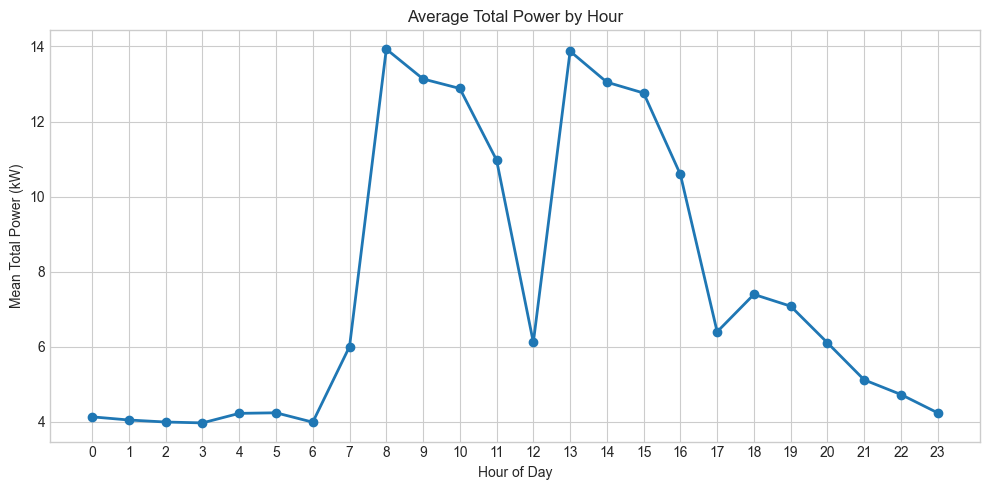

Saved: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/eda/average_system_power_by_floor.png


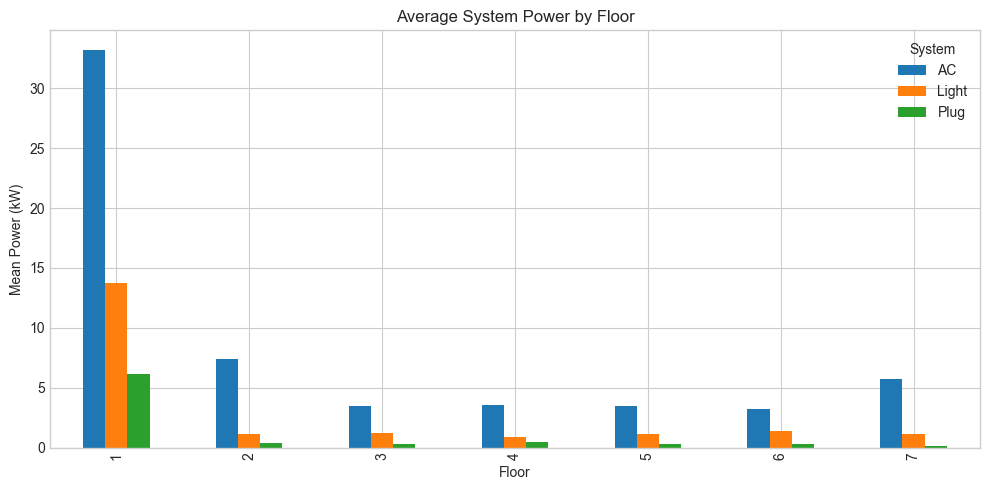

Saved: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/eda/missing_value_percentage_by_variable.png


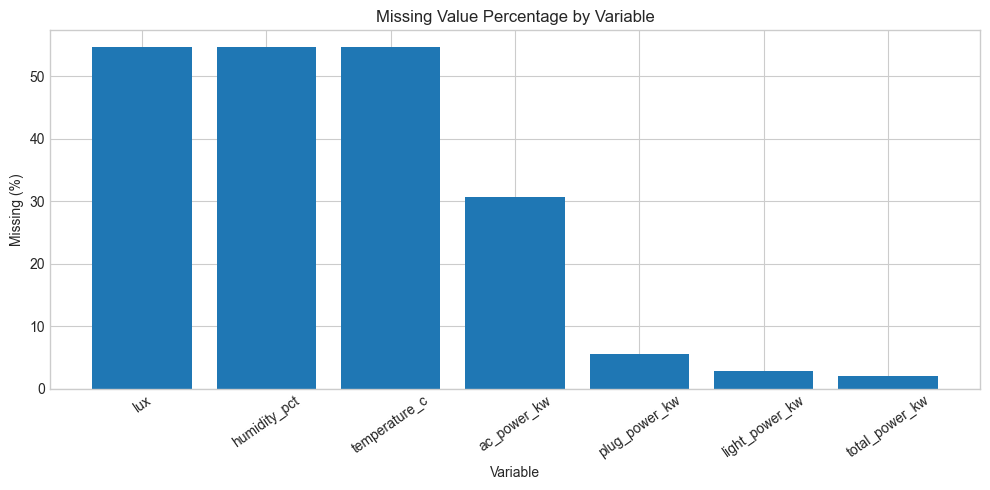

Saved: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/eda/average_total_power_by_day_of_week.png


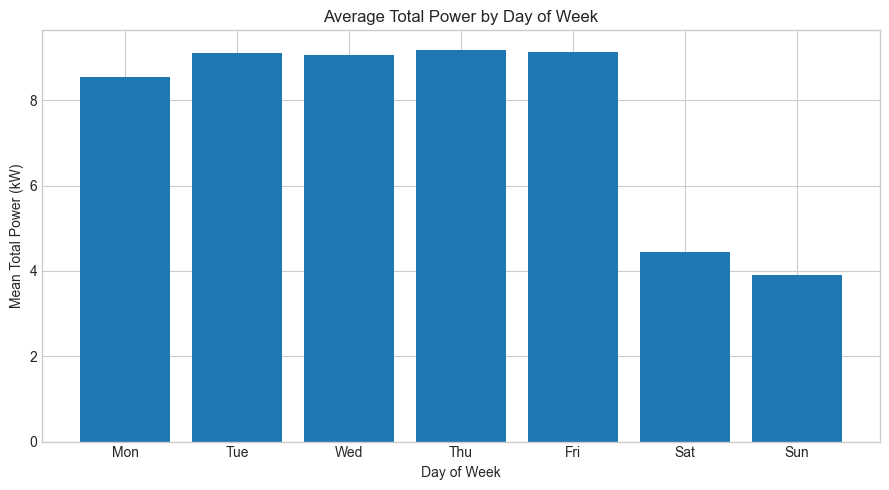

Saved: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/eda/floor_hour_total_power_heatmap.png


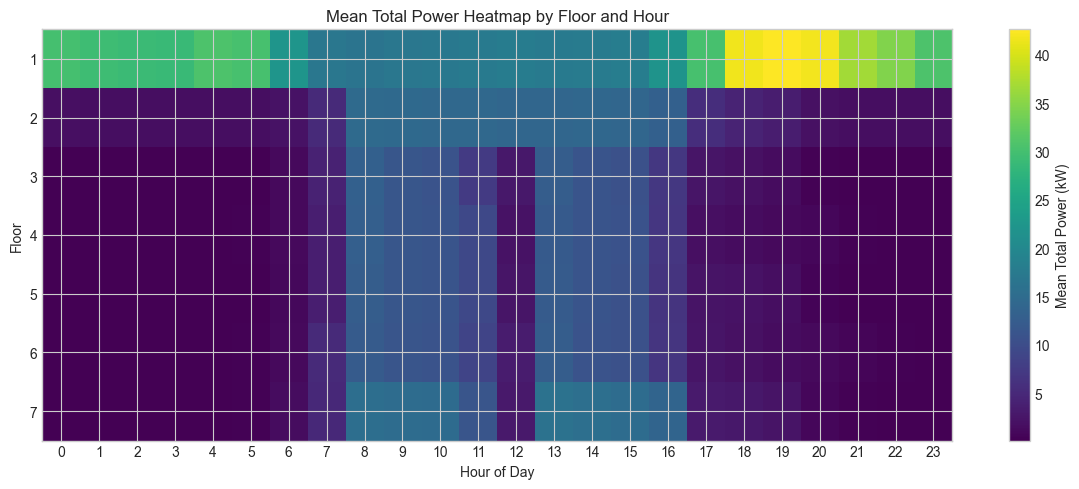

In [16]:
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")


def save_current_figure(filename: str) -> Path:
    path = EDA_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    print("Saved:", path)
    return path


# 1. Average total power by hour
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hour_summary["hour"], hour_summary["total_power_kw_mean"], marker="o", linewidth=2)
ax.set_title("Average Total Power by Hour")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Mean Total Power (kW)")
ax.set_xticks(range(0, 24))
save_current_figure("average_total_power_by_hour.png")
plt.show()

# 2. Average system power by floor
fig, ax = plt.subplots(figsize=(10, 5))
floor_plot = floor_summary.set_index("floor")[["ac_power_kw_mean", "light_power_kw_mean", "plug_power_kw_mean"]]
floor_plot.plot(kind="bar", ax=ax)
ax.set_title("Average System Power by Floor")
ax.set_xlabel("Floor")
ax.set_ylabel("Mean Power (kW)")
ax.legend(["AC", "Light", "Plug"], title="System")
save_current_figure("average_system_power_by_floor.png")
plt.show()

# 3. Missing percentage by variable
fig, ax = plt.subplots(figsize=(10, 5))
missing_plot = missing_summary.sort_values("missing_pct", ascending=False)
ax.bar(missing_plot["variable"], missing_plot["missing_pct"] * 100)
ax.set_title("Missing Value Percentage by Variable")
ax.set_xlabel("Variable")
ax.set_ylabel("Missing (%)")
ax.tick_params(axis="x", rotation=35)
save_current_figure("missing_value_percentage_by_variable.png")
plt.show()

# 4. Average total power by day of week
day_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(9, 5))
day_plot = day_of_week_summary.sort_values("day_of_week")
ax.bar([day_labels[int(day)] for day in day_plot["day_of_week"]], day_plot["total_power_kw_mean"])
ax.set_title("Average Total Power by Day of Week")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Mean Total Power (kW)")
save_current_figure("average_total_power_by_day_of_week.png")
plt.show()

# 5. Floor-hour heatmap
heatmap_data = floor_hour_summary.pivot(index="floor", columns="hour", values="total_power_kw_mean")
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(heatmap_data, aspect="auto", cmap="viridis")
ax.set_title("Mean Total Power Heatmap by Floor and Hour")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Floor")
ax.set_xticks(range(24))
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index.astype(int))
fig.colorbar(im, ax=ax, label="Mean Total Power (kW)")
save_current_figure("floor_hour_total_power_heatmap.png")
plt.show()

## 16. EDA interpretation checklist

看完上面的 summary 和图，下一步写报告或准备 baseline anomaly detection 时，重点记录：

- 哪些楼层/zone 的平均总能耗最高。
- AC、Light、Plug 哪一类系统贡献最大。
- 工作时间与非工作时间是否有明显差异。
- 周末和工作日是否有明显差异。
- 温度、湿度、照度的缺失比例是否会影响建模。
- 哪些楼层/zone 由于缺失或时间范围不足，需要单独说明。

完成这一轮 EDA 后，下一步可以做 rolling/time-series features，例如 15 分钟/60 分钟 rolling mean、rolling std、lag、difference 和按 `floor + zone + hour` 计算的 baseline z-score。

## 17. Count All NaN Values in Cleaned 15-Minute Table

This section counts all `NaN` values in the cleaned 15-minute feature table. It uses chunked reading, so it is safe for the current data size. The result is saved as `nan_summary_cleaned_15min.csv` in the `outputs` folder.

In [21]:
def find_project_dir(start=None):
    current = (start or Path.cwd()).resolve()
    for path in [current, *current.parents]:
        if path.name == PROJECT_NAME and (path / "outputs").exists():
            return path
        candidate = path / PROJECT_NAME
        if (candidate / "outputs").exists():
            return candidate
    raise FileNotFoundError(f"Could not find '{PROJECT_NAME}/outputs'.")

PROJECT_DIR = find_project_dir()
OUTPUT_DIR = PROJECT_DIR / "outputs"
file_path = OUTPUT_DIR / "cleaned_zone_15min_2018_2019.csv.gz"
NAN_SUMMARY_PATH = OUTPUT_DIR / "nan_summary_cleaned_15min.csv"

print("NaN input file:", file_path)
if not file_path.exists():
    raise FileNotFoundError(f"File not found: {file_path}")

nan_counts = None
total_rows = 0

for chunk_number, chunk in enumerate(pd.read_csv(file_path, chunksize=500_000), start=1):
    print(f"Checking chunk {chunk_number}: {len(chunk):,} rows")
    total_rows += len(chunk)
    chunk_nan_counts = chunk.isna().sum()

    if nan_counts is None:
        nan_counts = chunk_nan_counts
    else:
        nan_counts = nan_counts.add(chunk_nan_counts, fill_value=0)

nan_summary = pd.DataFrame({
    "column": nan_counts.index,
    "nan_count": nan_counts.values.astype(int),
    "nan_pct": nan_counts.values / total_rows * 100,
})

nan_summary = nan_summary.sort_values(["nan_pct", "nan_count"], ascending=False).reset_index(drop=True)
nan_summary.to_csv(NAN_SUMMARY_PATH, index=False)

print("Total rows checked:", f"{total_rows:,}")
print("Saved NaN summary to:", NAN_SUMMARY_PATH)
display(nan_summary.head(20))

NaN input file: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/cleaned_zone_15min_2018_2019.csv.gz
Checking chunk 1: 500,000 rows
Checking chunk 2: 500,000 rows
Checking chunk 3: 500,000 rows
Checking chunk 4: 205,422 rows
Total rows checked: 1,705,422
Saved NaN summary to: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/nan_summary_cleaned_15min.csv


,column,nan_count,nan_pct
0,lux,919270,53.902788
1,lux_min,919270,53.902788
2,lux_max,919270,53.902788
3,temperature_c,919266,53.902553
4,humidity_pct,919266,53.902553
5,temperature_c_min,919266,53.902553
6,humidity_pct_min,919266,53.902553
7,temperature_c_max,919266,53.902553
8,humidity_pct_max,919266,53.902553
9,ac_power_kw,520316,30.509516
